# ICT-26 — Convention de signalisation (expérience A, strate 7)

**Série ICT** | Précédent : [ICT-46b-BancUnique-Strate7](./ICT-46b-BancUnique-Strate7-Python.ipynb) | Suivant : [ICT-27-SymbolInvention](./ICT-27-SymbolInvention-Python.ipynb) | [↑ Série ICT](README.md)

*Compagnon pédagogique du module `ict.signaling_convention` (#7746, jambe D2 expérience A).*

Cette expérience est la **ligne de base « sans coup ontologique »** de la strate 7 :
le vocabulaire est **FIXE** — aucun symbole n'est inventé (c'est l'expérience B,
*ICT-27-SymbolInvention-Python*). On demande alors une chose précise et falsifiable :

> Partant de propensités **uniformes** (aucune signification pré-inscrite), un
> **code conventionnel** émerge-t-il spontanément par apprentissage par
> renforcement, et avec lui l'**information mutuelle** $I(\text{état} ; \text{signal})$
> qui mesure combien le signal en dit sur l'état ?

C'est le jeu de signalisation canonique de **David Lewis** (*Convention*, 1969) et
**Brian Skyrms** (*Signals*, 2010) : un émetteur observe l'état du monde et envoie
un signal ; un récepteur choisit une action ; le couple est récompensé quand
l'action correspond à l'état. Mécanisme d'apprentissage : **Roth-Erev** (softmax
avec température, annealing exploration→exploitation).

**Contraste avec B** : ici le vocabulaire est *donné* et bornant ; en B il est
*inventé* à la mesure du problème. Les deux notebooks se répondent : A montre ce
qu'un vocabulaire fixe **permet et borne**, B montre comment l'invention **lève**
la borne.
**Protocole multi-graines (#14439)** : chaque verdict est évalué sur les cinq
graines `0/1/7/42/99` avec des paramètres de simulation **strictement
identiques** (aucun retuning). Les grandeurs qui portent la conclusion sont
rapportées avec leur **dispersion inter-graines** (moyenne ± écart-type,
ddof=1), le verdict honnête compte les graines sur lesquelles il tient, et les
grandeurs déterministes (plafonds analytiques comme $\log_2 n$) sont
explicitement distinguées des grandeurs simulées.


> **Statut épistémique** — **soutenu dans le protocole courant** : Une convention de signalisation **émerge** par RL sans signification pré-inscrite (Lewis/Skyrms). Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

> **Acquis et parenté** : expérience **A** des cinq expériences A→E (ICT-26 → ICT-30), sur l'**axe transverse** (socle Thom, dimension D2, [#7745](https://github.com/jsboige/CoursIA/issues/7745)/[#7746](https://github.com/jsboige/CoursIA/issues/7746)) — pas une strate verticale. Les expériences B→E s'appuient sur la convention établie ici.


In [1]:
# Setup : import du package ict (via sys.path cwd, cf C973-L) + numpy/matplotlib.
import sys
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
from ict import signaling_convention as sc

publique = [n for n in dir(sc) if not n.startswith("_")]
print("ict.signaling_convention chargé.")
print("API publique :", publique)

# Protocole multi-graines (#14439) : une conclusion tirée d'un seul tirage ne se
# distingue pas d'un artefact de graine. Graines [0, 1, 7, 42, 99], paramètres
# inchangés d'une graine à l'autre — la dispersion mesure la variabilité du
# processus d'apprentissage (Roth-Erev + softmax), pas un réglage.
GRAINES = (0, 1, 7, 42, 99)

def synthese_multigraine(fonction_verdict, cles, cle_verdict, **kwargs):
    """Exécute un verdict pour chaque graine et rapporte la dispersion inter-graines.

    Affiche : valeurs par graine, comptage du verdict (X/N graines), puis moyenne
    et écart-type inter-graines (ddof=1) de chaque grandeur — la dispersion fait
    partie du résultat, pas un détail (#14439).
    """
    valeurs = {c: [] for c in cles}
    compte = 0
    for gr in GRAINES:
        r = fonction_verdict(seed=gr, **kwargs)
        ok = bool(r[cle_verdict])
        compte += int(ok)
        for c in cles:
            valeurs[c].append(r[c])
        detail = " | ".join(f"{c}={r[c]:.3f}" for c in cles)
        print(f"graine={gr:2d} | {cle_verdict}={ok!s:5} | {detail}")
    print(f"-> verdict {cle_verdict} : {compte}/{len(GRAINES)} graines")
    for c in cles:
        v = np.asarray(valeurs[c])
        print(f"   {c:26s} : {v.mean():.3f} +/- {v.std(ddof=1):.3f}"
              f"  (min {v.min():.3f}, max {v.max():.3f})")
    return valeurs, compte


ict.signaling_convention chargé.
API publique : ['Dict', 'Optional', 'Sequence', 'SignalingGame', 'Tuple', 'annotations', 'convention_stability_test', 'coordination_emerges_test', 'mi_tracks_meaning_test', 'mutual_information', 'np', 'vocabulary_bottleneck_test']


## 1. L'émergence sans signification pré-inscrite

Le verdict central : depuis des propensités **uniformes** (chaque signal aussi
bon qu'un autre au départ), un entraînement Roth-Erev fait-il émerger une
**convention** — c'est-à-dire un code où chaque état déclenche un signal
distinct, déclenchant à son tour la bonne action ?

On mesure deux quantités simultanément :

* le **taux de coordination** (succès : l'action correspond-elle à l'état ?) ;
* l'**information mutuelle** $I(\text{état} ; \text{signal})$, qui vaut $0$ si le
  signal n'informerait sur rien (*pooling* : un seul signal utilisé) et
  $\log_2(n_{\text{états}})$ si le signal code parfaitement l'état.

Un succès élevé **sans** information mutuelle serait suspect : ce serait une
coordination « par chance » ou par exploitation d'un biais, pas une convention
signifiante. Le verdict n'est satisfait que si les deux montent **ensemble** et
dominent nettement le contrôle sans-apprentissage.

graine= 0 | emerged=True  | learned_success=1.000 | learned_mi=1.993 | control_success=0.241 | control_mi=0.004


graine= 1 | emerged=True  | learned_success=1.000 | learned_mi=1.988 | control_success=0.256 | control_mi=0.009


graine= 7 | emerged=False | learned_success=0.750 | learned_mi=1.329 | control_success=0.230 | control_mi=0.003


graine=42 | emerged=True  | learned_success=1.000 | learned_mi=1.998 | control_success=0.259 | control_mi=0.007


graine=99 | emerged=True  | learned_success=1.000 | learned_mi=1.995 | control_success=0.246 | control_mi=0.005
-> verdict emerged : 4/5 graines
   learned_success            : 0.950 +/- 0.112  (min 0.750, max 1.000)
   learned_mi                 : 1.861 +/- 0.297  (min 1.329, max 1.998)
   control_success            : 0.246 +/- 0.012  (min 0.230, max 0.259)
   control_mi                 : 0.006 +/- 0.003  (min 0.003, max 0.009)
(contrôle = agents qui jouent leur politique uniforme SANS apprendre)
(max_mi = 2.000 bits : déterministe — constante analytique log2(n_states), non simulée)


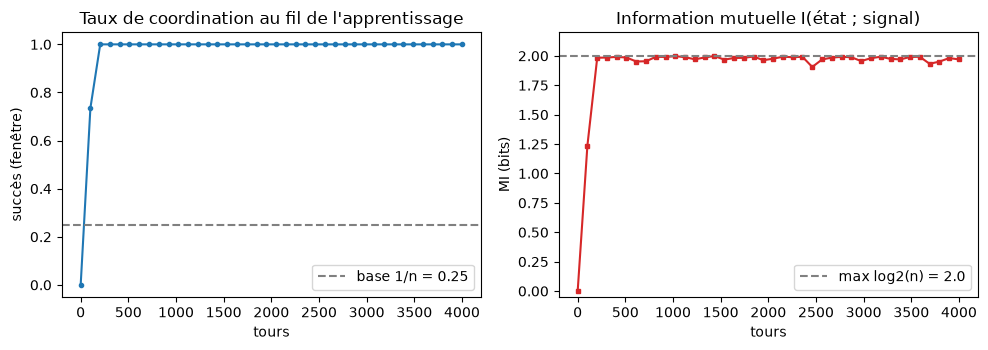

In [2]:
# Verdict EMERGENCE multi-graines [0, 1, 7, 42, 99] (#14439) : n_states=4,
# n_signals=4, paramètres par défaut inchangés (n_rounds=4000, temperature=0.6,
# anneal_to=0.15, window=800) — aucun retuning, seule la graine varie.
cles_emergence = ("learned_success", "learned_mi", "control_success", "control_mi")
valeurs_emergence, n_emerged = synthese_multigraine(
    sc.coordination_emerges_test, cles_emergence, "emerged",
    n_states=4, n_signals=4)
print("(contrôle = agents qui jouent leur politique uniforme SANS apprendre)")
print("(max_mi = 2.000 bits : déterministe — constante analytique log2(n_states), non simulée)")

# Trajectoire illustrative (graine 0, mêmes paramètres) : succès glissant +
# information mutuelle glissante au fil des tours.
g = sc.SignalingGame(4, 4, temperature=0.6, rng=np.random.default_rng(0))
tours, succ, mi = sc._trajectory(g, 4000, anneal_to=0.15)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(tours, succ, "-o", ms=3, color="#1f77b4")
ax[0].axhline(0.25, ls="--", color="grey", label="base 1/n = 0.25")
ax[0].set_title("Taux de coordination au fil de l'apprentissage")
ax[0].set_xlabel("tours") ; ax[0].set_ylabel("succès (fenêtre)") ; ax[0].set_ylim(-0.05, 1.05)
ax[0].legend(loc="lower right")
ax[1].plot(tours, mi, "-s", ms=3, color="#d62728")
ax[1].axhline(np.log2(4), ls="--", color="grey", label="max log2(n) = 2.0")
ax[1].set_title("Information mutuelle I(état ; signal)")
ax[1].set_xlabel("tours") ; ax[1].set_ylabel("MI (bits)") ; ax[1].set_ylim(-0.05, 2.2)
ax[1].legend(loc="lower right")
fig.tight_layout() ; plt.show()


### Lecture multi-graines — l'émergence tient 4 fois sur 5

**Sortie obtenue** : sur les 5 graines `[0, 1, 7, 42, 99]` (paramètres identiques, aucun retuning), le verdict `emerged` tombe **4/5**.

| Grandeur (simulée, stochastique) | Moyenne ± écart-type (ddof=1) | Min–Max |
|---|---|---|
| succès appris | 0.950 ± 0.112 | 0.750 – 1.000 |
| MI apprise (bits) | 1.861 ± 0.297 | 1.329 – 1.998 |
| succès contrôle (sans apprentissage) | 0.246 ± 0.012 | 0.230 – 0.259 |
| MI contrôle (bits) | 0.006 ± 0.003 | 0.003 – 0.009 |

**Points clés** :
1. Quatre graines convergent vers la convention quasi parfaite : succès 1.000, MI ≈ 1.99 bits — au plafond $\log_2 4 = 2.000$ bits.
2. La **graine 7 tombe dans un piège de pooling partiel** : succès 0.750 (sous le seuil 0.8), MI 1.329 — trois états codés, le quatrième reste confondu. Le verdict échoue sur cette graine ; on ne retune pas les paramètres pour masquer l'échec (c'est la lecture honnête demandée par #14439).
3. Le contrôle sans apprentissage est quasi déterministe en pratique : succès ≈ 0.25 (= base $1/n$), MI ≈ 0. L'écart apprenti/contrôle ne doit donc rien au choix de la graine.

**Verdict honnête** : la conclusion qualitative — une convention signifiante émerge sans signification pré-inscrite — **survit sur 4 graines sur 5**, pas sur toutes : sous ces paramètres exacts, 1 graine sur 5 dans cet échantillon reste piégée en pooling partiel (exercice 1 : c'est précisément ce que le réglage de la température doit éviter). Éléments **déterministes** : `max_mi = log2(n_states) = 2.000` bits et les seuils du verdict (0.8 ; 0.5·max_mi ; écarts > 0.3) — constantes analytiques, non simulées. La trajectoire ci-dessus illustre une graine convergente (graine 0).


## 2. Le goulot de vocabulaire — ce que le FIXE borne

L'expérience A a un paramètre que B viendra exactement *déverrouiller* : la
**taille du vocabulaire** $n_{\text{signaux}}$. Avec $M < N$ signaux pour $N$
états, **aucun code** ne peut distinguer tous les états : c'est une borne de
**théorie de l'information**, pas une limite d'apprentissage. Le plafond de
signification est $\log_2(M)$.

On balaie $n_{\text{signaux}}$ de 1 à $N$ sous entraînement identique et on
observe le succès et la signification atteints. La courbe doit suivre le plafond
de codage — c'est précisément ce plafond que l'invention (expérience B) vient
pousser.

graine= 0 | bottleneck=True  | mi_full_vocab=1.993 | mi_limited_vocab=0.506 | ratio_limited_over_full=0.254


graine= 1 | bottleneck=True  | mi_full_vocab=1.988 | mi_limited_vocab=0.460 | ratio_limited_over_full=0.231


graine= 7 | bottleneck=True  | mi_full_vocab=1.329 | mi_limited_vocab=0.477 | ratio_limited_over_full=0.359


graine=42 | bottleneck=True  | mi_full_vocab=1.998 | mi_limited_vocab=0.492 | ratio_limited_over_full=0.246


graine=99 | bottleneck=True  | mi_full_vocab=1.995 | mi_limited_vocab=0.480 | ratio_limited_over_full=0.241
-> verdict bottleneck : 5/5 graines
   mi_full_vocab              : 1.861 +/- 0.297  (min 1.329, max 1.998)
   mi_limited_vocab           : 0.483 +/- 0.017  (min 0.460, max 0.506)
   ratio_limited_over_full    : 0.266 +/- 0.053  (min 0.231, max 0.359)
(plafonds de codage déterministes : log2(4)=2.000 bits plein vocabulaire, log2(2)=1.000 bit vocabulaire limité — constantes analytiques)


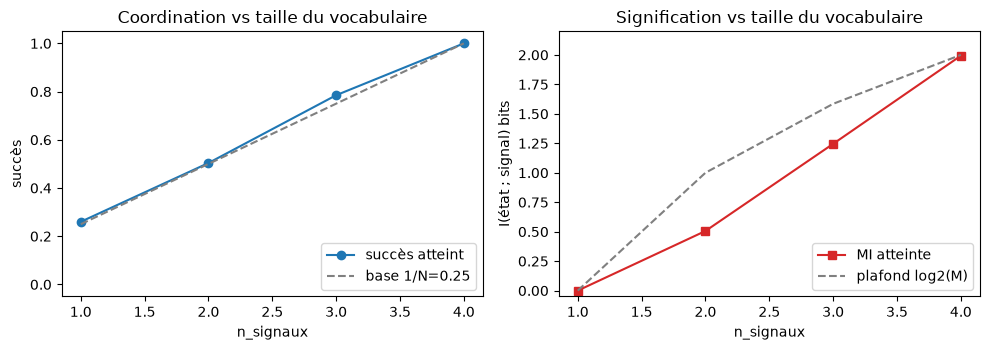

In [3]:
# Verdict GOULOT multi-graines [0, 1, 7, 42, 99] (#14439) : n_states=4,
# paramètres par défaut inchangés (n_rounds=4000, temperature=0.6, anneal_to=0.15).
cles_goulot = ("mi_full_vocab", "mi_limited_vocab", "ratio_limited_over_full")
valeurs_goulot, n_bottleneck = synthese_multigraine(
    sc.vocabulary_bottleneck_test, cles_goulot, "bottleneck", n_states=4)
print("(plafonds de codage déterministes : log2(4)=2.000 bits plein vocabulaire,"
      " log2(2)=1.000 bit vocabulaire limité — constantes analytiques)")

# Balayage : succès + MI en fonction du nombre de signaux disponibles
# (graine 0, illustration — le verdict multi-graines ci-dessus porte la conclusion).
n_states = 4
nsigs = list(range(1, n_states + 1))
succ_sweep, mi_sweep = [], []
for nsig in nsigs:
    g = sc.SignalingGame(n_states, nsig, temperature=0.6, rng=np.random.default_rng(0))
    g.train(4000, anneal_to=0.15)
    g.joint_state_signal[:] = 0.0
    for _ in range(800):
        g.play_round(reinforce=False)
    succ_sweep.append(g.success_rate(800))
    mi_sweep.append(sc.mutual_information(g.joint_state_signal))
ceiling = [np.log2(max(n, 1)) for n in nsigs]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(nsigs, succ_sweep, "-o", color="#1f77b4", label="succès atteint")
ax[0].plot(nsigs, [n / n_states for n in nsigs], "--", color="grey", label=f"base 1/N={1/n_states:.2f}")
ax[0].set_title("Coordination vs taille du vocabulaire") ; ax[0].set_xlabel("n_signaux")
ax[0].set_ylabel("succès") ; ax[0].set_ylim(-0.05, 1.05) ; ax[0].legend(loc="lower right")
ax[1].plot(nsigs, mi_sweep, "-s", color="#d62728", label="MI atteinte")
ax[1].plot(nsigs, ceiling, "--", color="grey", label="plafond log2(M)")
ax[1].set_title("Signification vs taille du vocabulaire") ; ax[1].set_xlabel("n_signaux")
ax[1].set_ylabel("I(état ; signal) bits") ; ax[1].set_ylim(-0.05, 2.2) ; ax[1].legend(loc="lower right")
fig.tight_layout() ; plt.show()


### Lecture multi-graines — le goulot est le verdict le plus robuste (5/5)

**Sortie obtenue** : verdict `bottleneck` **5/5** graines.

| Grandeur (simulée, stochastique) | Moyenne ± écart-type (ddof=1) | Min–Max |
|---|---|---|
| MI vocabulaire plein (4 signaux, bits) | 1.861 ± 0.297 | 1.329 – 1.998 |
| MI vocabulaire limité (2 signaux, bits) | 0.483 ± 0.017 | 0.460 – 0.506 |
| ratio limité / plein | 0.266 ± 0.053 | 0.231 – 0.359 |

**Points clés** :
1. Seul verdict **unanime 5/5** : sur aucune graine la MI du vocabulaire limité ne s'approche de celle du vocabulaire plein — l'écart (facteur ≈ 3.8 en moyenne) ne se referme jamais.
2. La MI limitée est aussi la grandeur la **moins dispersée** du notebook (écart-type 0.017 bit) : le goulot borne la signification de façon reproductible, indépendamment du tirage.
3. La MI limitée (≈ 0.48 bit) reste sous le plafond théorique $\log_2 2 = 1.000$ bit : les agents convergent vers un pooling partiel. La MI seule ne permet pas d'identifier de façon unique la partition des quatre états entre les deux signaux.

**Verdict honnête** : la conclusion survit **sur les 5 graines** — un vocabulaire FIXE insuffisant borne strictement la signification (borne de théorie de l'information, pas un échec d'apprentissage). Éléments **déterministes** : les plafonds $\log_2(M)$ (constantes analytiques).


## 3. Succès ≠ signification — le contrôle à état dominant

Un taux de coordination élevé ne prouve pas qu'une convention *signifiante* s'est
formée. Le contrôle falsifiant : un jeu avec un **état dominant** (un état
représente 85 % des tirages). Les agents peuvent atteindre un succès élevé en
apprenant à **toujours choisir l'action de l'état dominant** — sans que le signal
ne porte la moindre information (MI faible).

Le verdict `mi_tracks_meaning` exige donc que succès et information mutuelle
**croissent ensemble** (corrélation forte sur la trajectoire), ET que le contrôle
à état dominant montre un succès comparable mais une MI nettement plus faible.
C'est ce qui distingue « réussir *via* signification » de « réussir *via*
exploitation d'un biais ».

In [4]:
# Verdict SENS multi-graines [0, 1, 7, 42, 99] (#14439) : n_states=4,
# paramètres par défaut inchangés (n_rounds=3000, temperature=0.6, anneal_to=0.15).
cles_sens = ("balanced_final_success", "balanced_final_mi", "balanced_corr_mi_success",
             "dominant_final_success", "dominant_final_mi")
valeurs_sens, n_meaningful = synthese_multigraine(
    sc.mi_tracks_meaning_test, cles_sens, "meaningful", n_states=4)
print()
print("Lecture : cas équilibré — succès ET MI élevés (signification) ;")
print("          cas dominant  — succès comparable MAIS MI nettement plus faible (pas de signification).")


graine= 0 | meaningful=True  | balanced_final_success=1.000 | balanced_final_mi=1.970 | balanced_corr_mi_success=0.983 | dominant_final_success=0.961 | dominant_final_mi=0.855


graine= 1 | meaningful=True  | balanced_final_success=1.000 | balanced_final_mi=1.961 | balanced_corr_mi_success=0.993 | dominant_final_success=1.000 | dominant_final_mi=1.145


graine= 7 | meaningful=True  | balanced_final_success=0.714 | balanced_final_mi=1.233 | balanced_corr_mi_success=0.767 | dominant_final_success=1.000 | dominant_final_mi=0.902


graine=42 | meaningful=True  | balanced_final_success=1.000 | balanced_final_mi=1.984 | balanced_corr_mi_success=0.978 | dominant_final_success=1.000 | dominant_final_mi=0.852


graine=99 | meaningful=True  | balanced_final_success=1.000 | balanced_final_mi=1.947 | balanced_corr_mi_success=0.993 | dominant_final_success=1.000 | dominant_final_mi=0.627
-> verdict meaningful : 5/5 graines
   balanced_final_success     : 0.943 +/- 0.128  (min 0.714, max 1.000)
   balanced_final_mi          : 1.819 +/- 0.328  (min 1.233, max 1.984)
   balanced_corr_mi_success   : 0.943 +/- 0.098  (min 0.767, max 0.993)
   dominant_final_success     : 0.992 +/- 0.017  (min 0.961, max 1.000)
   dominant_final_mi          : 0.876 +/- 0.184  (min 0.627, max 1.145)

Lecture : cas équilibré — succès ET MI élevés (signification) ;
          cas dominant  — succès comparable MAIS MI nettement plus faible (pas de signification).


### Lecture multi-graines — succès et signification croissent ensemble (5/5), avec une nuance

**Sortie obtenue** : verdict `meaningful` **5/5** graines.

| Grandeur (simulée, stochastique) | Moyenne ± écart-type (ddof=1) | Min–Max |
|---|---|---|
| succès final équilibré | 0.943 ± 0.128 | 0.714 – 1.000 |
| MI finale équilibrée (bits) | 1.819 ± 0.328 | 1.233 – 1.984 |
| corrélation MI–succès (trajectoire) | 0.943 ± 0.098 | 0.767 – 0.993 |
| succès final dominant (contrôle) | 0.992 ± 0.017 | 0.961 – 1.000 |
| MI finale dominante (contrôle, bits) | 0.876 ± 0.184 | 0.627 – 1.145 |

**Points clés** :
1. La corrélation MI–succès ne descend jamais sous 0.767 : les deux quantités croissent ensemble sur **toutes** les trajectoires, y compris la graine 7 (pooling partiel de la §1).
2. **Nuance honnête** : le contrôle à état dominant n'a **pas** une MI nulle (≈ 0.88 bit en moyenne). C'est attendu — même un code opportuniste gagne à distinguer l'état dominant (85 %) des autres, l'entropie de $[0.85, 0.05, 0.05, 0.05]$ étant ≈ 0.85 bit (et l'estimation empirique sur fenêtre courte ≈ 77 tours la surestime légèrement, biais positif). La « MI faible » du contrôle est faible **relativement** à la MI équilibrée — l'écart vaut ≥ 0.331 bit sur les 5 graines (seuil 0.3, jamais franchi) — pas absolument.
3. La graine 7 frôle le seuil (écart 0.331) : même racine que le pooling partiel de la §1 — la MI équilibrée baisse plus vite que la MI du contrôle.

**Verdict honnête** : la conclusion survit **sur les 5 graines**, mais le discriminateur est « ≈ la moitié du maximum contre ≈ le maximum », pas « MI nulle contre MI pleine » — la §3 gagne à être lue avec cette précision.


## 4. Stabilité de la convention — résistance aux chocs

Une convention établie est-elle **robuste** ? On entraîne une convention (succès
élevé), puis on perturbe les propensités en injectant du bruit additif **relatif**
à l'échelle des propensités elles-mêmes (en multiples de leur écart-type). Un
choc absolu serait négligeable : après des milliers de renforcements, les $Q$
atteignent des centaines.

* un choc **modéré** (≈ 0,5 écart-type) laisse la structure apprise dominante ;
* un choc **brutal** (≈ 6 écarts-types) l'oblitère.

Une convention stable résiste au choc modéré et se reconstruit vite par
ré-apprentissage ; le choc brutal l'effondre nettement plus.

In [5]:
# Verdict STABILITÉ multi-graines [0, 1, 7, 42, 99] (#14439) : n_states=4,
# chocs inchangés (modéré = 0.5 écart-type, brutal = 6 écarts-types).
cles_stabilite = ("established_success", "moderate_immediate", "moderate_recovered",
                  "brutal_immediate", "brutal_recovered")
valeurs_stabilite, n_stable = synthese_multigraine(
    sc.convention_stability_test, cles_stabilite, "stable", n_states=4)
print()
print("Lecture : choc modéré -> succès immédiat élevé (résiste), récupération rapide ;")
print("          choc brutal  -> succès immédiat effondré (la convention est détruite).")


graine= 0 | stable=True  | established_success=1.000 | moderate_immediate=1.000 | moderate_recovered=1.000 | brutal_immediate=0.247 | brutal_recovered=0.242


graine= 1 | stable=True  | established_success=1.000 | moderate_immediate=1.000 | moderate_recovered=1.000 | brutal_immediate=0.000 | brutal_recovered=0.000


graine= 7 | stable=False | established_success=0.750 | moderate_immediate=0.746 | moderate_recovered=0.738 | brutal_immediate=0.271 | brutal_recovered=0.250


graine=42 | stable=True  | established_success=1.000 | moderate_immediate=1.000 | moderate_recovered=1.000 | brutal_immediate=0.250 | brutal_recovered=0.269


graine=99 | stable=True  | established_success=1.000 | moderate_immediate=1.000 | moderate_recovered=1.000 | brutal_immediate=0.274 | brutal_recovered=0.266
-> verdict stable : 4/5 graines
   established_success        : 0.950 +/- 0.112  (min 0.750, max 1.000)
   moderate_immediate         : 0.949 +/- 0.113  (min 0.746, max 1.000)
   moderate_recovered         : 0.948 +/- 0.117  (min 0.738, max 1.000)
   brutal_immediate           : 0.208 +/- 0.117  (min 0.000, max 0.274)
   brutal_recovered           : 0.205 +/- 0.115  (min 0.000, max 0.269)

Lecture : choc modéré -> succès immédiat élevé (résiste), récupération rapide ;
          choc brutal  -> succès immédiat effondré (la convention est détruite).


### Lecture multi-graines — stabilité 4/5, même racine que la §1

**Sortie obtenue** : verdict `stable` **4/5** graines.

| Grandeur (simulée, stochastique) | Moyenne ± écart-type (ddof=1) | Min–Max |
|---|---|---|
| succès établi (avant choc) | 0.950 ± 0.112 | 0.750 – 1.000 |
| choc modéré — succès immédiat | 0.949 ± 0.113 | 0.746 – 1.000 |
| choc modéré — reconstruit | 0.948 ± 0.117 | 0.738 – 1.000 |
| choc brutal — succès immédiat | 0.208 ± 0.117 | 0.000 – 0.274 |
| choc brutal — reconstruit | 0.205 ± 0.115 | 0.000 – 0.269 |

**Points clés** :
1. Le patron qualitatif — choc modéré **supporté** (immédiat ≈ reconstruit ≈ établi), choc brutal **effondrant** — est **identique sur les 5 graines** : l'écart immédiat modéré−brutal vaut 0.741 ± 0.186 en moyenne et ne descend jamais sous 0.475 (seuil 0.3 toujours franchi).
2. La graine 7 échoue aux seuils d'établissement et de reconstruction modérée : 0.750 et 0.738 restent sous 0.8. Ces deux écarts ont la **même racine** que le pooling partiel de la §1 (même entraînement, même graine) ; le choc modéré préserve néanmoins le plafond atteint, et l'écart face au choc brutal reste conforme.
3. Après choc brutal, 800 tours de ré-apprentissage ne reconstruisent rien (moyenne 0.205) : cohérent avec les ~4000 tours nécessaires à l'émergence initiale — une convention détruite repart de près de zéro.

**Verdict honnête** : la conclusion (résistance au choc modéré, effondrement sous choc brutal) survit **qualitativement sur les 5 graines** ; le verdict binaire `stable` tombe à 4/5 parce que la graine 7 reste sous les seuils d'établissement et de reconstruction, pour la raison déjà documentée en §1.


## 4bis. Gate de dégénérescence : les instruments savent-ils lire un code connu ?

Les quatre verdicts ci-dessus reposent sur deux instruments : `success_rate()` (le taux de
coordination) et `mutual_information(joint_state_signal)` (en bits). Avant de conclure quoi
que ce soit sur l'**émergence** d'une convention, il faut vérifier qu'ils savent lire un cas
dont la réponse est **connue d'avance** — sans quoi un succès mesuré ne prouve rien sur ce
qu'il prétend mesurer.

Trois cas de référence sont posés ici, dont deux **déterministes** :

* **G1 — code identité imposé.** On force les propensités à coder $0 \to 0$, $1 \to 1$, etc.
  Le taux de coordination doit valoir **exactement** 1, et l'information mutuelle doit égaler
  l'entropie de la marginale d'état **de l'échantillon**.
* **G1b — code confondu.** Les quatre états émettent **le même** signal et le récepteur répond
  toujours la même action. Le signal ne porte alors aucune information : la MI doit valoir
  **exactement 0**, sans biais d'estimation possible (une seule colonne ne peut pas en créer).
* **G2 — contrôle uniforme.** Propensités intactes, agents sans apprentissage : le signal est
  indépendant de l'état, donc la MI mesurée ne doit être qu'un résidu d'estimateur.

**Le piège que ce gate doit lui-même éviter.** Une référence naïve compare la MI de G1 à la
constante analytique $\log_2 4 = 2$. Or l'instrument estime sur un **échantillon fini** :
800 tirages uniformes n'ont pas une marginale d'état exactement plate, donc l'entropie de
l'échantillon est **inférieure** à 2 bits — et une MI parfaite vaut exactement cette entropie
empirique. Comparer à la constante **déclare cassé un instrument sain**. La première version
de ce gate a échoué de cette façon ; la référence correcte est l'entropie de la marginale
**observée**.

Une dernière porte (**G3**) vérifie que le résidu de G2 n'est pas un défaut mais le **biais
connu de l'estimateur plug-in**, dont la valeur moyenne sur un signal indépendant est
$(K-1)(L-1) / (2N \ln 2)$ bits : il doit décroître en $1/N$ comme cette prédiction.


In [6]:
# --- Gate de degenerescence des instruments de ICT-26 (issue #20300) ---
# Les quatre verdicts du carnet reposent sur success_rate() et mutual_information().
# Cette porte verifie d'abord que ces instruments savent lire un cas dont la reponse
# est connue d'avance : sans cela, un succes mesure ne prouve rien.
import math


def code_impose(n, emetteur, recepteur, temperature=1e-3, rng=None):
    """Installe un code deterministe (etat -> signal -> action) dans les propensites."""
    g = sc.SignalingGame(n, n, temperature=temperature,
                         rng=rng if rng is not None else np.random.default_rng(0))
    g.Q_s = np.full((n, n), 1.0)
    g.Q_r = np.full((n, n), 1.0)
    for s in range(n):
        g.Q_s[s, emetteur[s]] += 1000.0
    for m in range(n):
        g.Q_r[m, recepteur[m]] += 1000.0
    return g


def mesure(g, n_rounds=800):
    """Taux de coordination et MI sur n_rounds tours, sans apprentissage."""
    g.joint_state_signal[:] = 0.0
    for _ in range(n_rounds):
        g.play_round(reinforce=False)
    return g.success_rate(n_rounds), sc.mutual_information(g.joint_state_signal)


def entropie_marginale(joint):
    """Entropie (bits) de la marginale d'etat telle qu'observee dans l'echantillon."""
    p = joint / joint.sum()
    p_x = p.sum(axis=1)
    p_x = p_x[p_x > 0]
    return float(-(p_x * np.log2(p_x)).sum())


def entropie_signal(joint):
    """Entropie (bits) de la marginale de signal -- H(signal) = 0 <=> signal constant."""
    p = joint / joint.sum()
    p_m = p.sum(axis=0)
    p_m = p_m[p_m > 0]
    return float(-(p_m * np.log2(p_m)).sum())


n = 4

# G1 -- temoin positif : code identite impose. La reference n'est PAS la constante
# log2(n) mais l'entropie de la marginale d'etat de l'ECHANTILLON : 800 tirages
# uniformes n'ont pas une marginale exactement plate.
g1 = code_impose(n, list(range(n)), list(range(n)))
succ_g1, mi_g1 = mesure(g1)
h_g1 = entropie_marginale(g1.joint_state_signal)
g1_ok = (abs(succ_g1 - 1.0) < 1e-12) and (abs(mi_g1 - h_g1) < 1e-12)

# G1b -- zero exact : les quatre etats emettent le meme signal, le recepteur repond
# toujours la meme action. Deux verifications de nature differente :
#   (a) H(signal) = 0 EXACTEMENT : le signal est constant dans l'echantillon, donc
#       une colonne unique ne peut fabriquer aucune fausse dependance -- c'est la
#       raison structurelle du zero, et elle se mesure independamment de la MI ;
#   (b) succes == frequence de l'etat 0 : c'est une IDENTITE du code impose (succes
#       si et seulement si l'etat vaut 0), pas une mesure independante. Elle croise
#       les compteurs du jeu avec la table jointe ; elle ne prouve pas l'absence
#       d'information -- (a) le fait.
g1b = code_impose(n, [0] * n, [0] * n)
succ_g1b, mi_g1b = mesure(g1b)
freq_0 = g1b.joint_state_signal[0].sum() / g1b.joint_state_signal.sum()
h_g1b_signal = entropie_signal(g1b.joint_state_signal)
g1b_ok = (h_g1b_signal == 0.0) and (mi_g1b == 0.0) and (abs(succ_g1b - freq_0) < 1e-12)

# G2 -- temoin negatif : propensites uniformes, agents sans apprentissage. Le signal
# est independant de l'etat : succes ~ 1/n, MI ~ residu d'estimateur seulement.
g2 = sc.SignalingGame(n, n, temperature=0.6, rng=np.random.default_rng(0))
succ_g2, mi_g2 = mesure(g2)
sigma = math.sqrt(0.25 * 0.75 / 800)
g2_ok = (mi_g2 < 0.05) and (abs(succ_g2 - 1.0 / n) < 3 * sigma)

# G3 -- calibration : sur un signal independant, la MI du plug-in vaut en moyenne
# (K-1)(L-1)/(2 N ln 2) bits. Trois exigences, de la plus faible a la plus forte :
#   - le rapport mesure/prediction reste dans +/-25 % a chaque taille (echelle) ;
#   - la moyenne decroit STRICTEMENT quand N quadruple (sens de la loi) ;
#   - le facteur de decroissance entre deux tailles successives tombe dans [2, 8] :
#     la loi predit 4, et la fenetre est large sur la prediction, etroite sur
#     "ne decroit pas".
print("G3 -- biais de l'estimateur plug-in : moyenne 5 graines contre prediction analytique")
moyennes = {}
ratio_ok = True
for N in (200, 800, 3200):
    mIs = []
    for gr in (0, 1, 7, 42, 99):
        gg = sc.SignalingGame(n, n, temperature=0.6, rng=np.random.default_rng(gr))
        _, mi_N = mesure(gg, N)
        mIs.append(mi_N)
    moyenne = float(np.mean(mIs))
    moyennes[N] = moyenne
    predit = (n - 1) * (n - 1) / (2 * N * math.log(2))
    ratio = moyenne / predit
    ok = 0.75 <= ratio <= 1.25
    ratio_ok = ratio_ok and ok
    print(f"  N={N:5d}  MI moyenne={moyenne:.4f} (min {min(mIs):.4f} max {max(mIs):.4f})"
          f"  prediction={predit:.4f}  ratio={ratio:.2f}  {'OK' if ok else 'ECART'}")

paliers = ((200, 800), (800, 3200))
decroit_ok = all(moyennes[a] > moyennes[b] for a, b in paliers)
facteurs = {p: moyennes[p[0]] / moyennes[p[1]] for p in paliers}
pente_ok = all(2.0 <= f <= 8.0 for f in facteurs.values())
g3_ok = ratio_ok and decroit_ok and pente_ok
print("  decroissance en 1/N : " + "  ".join(
    f"{a}->{b} x{facteurs[(a, b)]:.2f} (attendu 4)" for a, b in paliers))

print()
print(f"G1  positif identite        succes={succ_g1:.6f}  MI={mi_g1:.6f}  H(etat)={h_g1:.6f}"
      f"  -> {'PASSED' if g1_ok else 'FAILED'}")
print(f"G1b zero exact confondu     succes={succ_g1b:.6f}  freq(etat0)={freq_0:.6f}"
      f"  H(signal)={abs(h_g1b_signal):.1f}  MI={mi_g1b:.6f}  -> {'PASSED' if g1b_ok else 'FAILED'}")
print(f"G2  negatif uniforme        succes={succ_g2:.6f}  MI={mi_g2:.6f}"
      f"  -> {'PASSED' if g2_ok else 'FAILED'}")
print(f"G3  calibration du biais    echelle {'OK' if ratio_ok else 'ECART'}"
      f" | decroissance {'OK' if decroit_ok else 'ECART'}"
      f" | pente {'OK' if pente_ok else 'ECART'}"
      f"  -> {'PASSED' if g3_ok else 'FAILED'}")
print()
print("VERDICT GLOBAL : instruments SAINS" if all([g1_ok, g1b_ok, g2_ok, g3_ok])
      else "VERDICT GLOBAL : GATE FAILED")


G3 -- biais de l'estimateur plug-in : moyenne 5 graines contre prediction analytique
  N=  200  MI moyenne=0.0373 (min 0.0154 max 0.0727)  prediction=0.0325  ratio=1.15  OK


  N=  800  MI moyenne=0.0083 (min 0.0049 max 0.0166)  prediction=0.0081  ratio=1.03  OK


  N= 3200  MI moyenne=0.0023 (min 0.0009 max 0.0037)  prediction=0.0020  ratio=1.13  OK
  decroissance en 1/N : 200->800 x4.47 (attendu 4)  800->3200 x3.65 (attendu 4)

G1  positif identite        succes=1.000000  MI=1.997361  H(etat)=1.997361  -> PASSED
G1b zero exact confondu     succes=0.271250  freq(etat0)=0.271250  H(signal)=0.0  MI=0.000000  -> PASSED
G2  negatif uniforme        succes=0.241250  MI=0.016582  -> PASSED
G3  calibration du biais    echelle OK | decroissance OK | pente OK  -> PASSED

VERDICT GLOBAL : instruments SAINS


### Lecture du verdict — instruments sains, et un résidu entièrement expliqué

**Sortie obtenue** : les **quatre** portes passent.

| Porte | Ce qu'elle impose | Mesure | Verdict |
|---|---|---|---|
| **G1** | Code identité imposé : coordination parfaite, MI égale à l'entropie de la marginale d'état | succès **1,000000**, MI **1,997361** bit pour $H(\hat\pi_{\text{état}}) = 1,997361$ — égalité à $10^{-12}$ près | **PASSED** |
| **G1b** | Code confondu : un seul signal, une seule action | H(signal) **exactement 0**, MI **exactement 0,000000** ; succès **0,271250** = fréquence observée de l'état 0, qui est une **identité** du code imposé et non une mesure indépendante | **PASSED** |
| **G2** | Propensités uniformes, agents sans apprentissage | succès **0,241250** (base $1/4$, écart $< 3\sigma$), MI **0,0166** bit | **PASSED** |
| **G3** | Le résidu de G2 est le biais du plug-in, prédit par $(K-1)(L-1)/(2N\ln 2)$ : échelle à $\pm 25$ %, décroissance stricte, facteur de décroissance voisin de 4 | $N=200$ : 0,0373 mesuré pour 0,0325 prédit (ratio 1,15) ; $N=800$ : 0,0083 pour 0,0081 (1,03) ; $N=3200$ : 0,0023 pour 0,0020 (1,13) ; paliers **×4,47** puis **×3,65** | **PASSED** |

**Ce que la porte apprend au carnet**, et c'est le point de méthode :

1. **Une MI parfaite vaut $H(\hat\pi_{\text{état}})$, pas $\log_2 n$.** L'écart entre 1,997361 et
   2,000000 n'est pas un défaut d'instrument : c'est le déficit d'entropie de la marginale
   d'état sur 800 tirages. Comparer à la constante analytique aurait déclaré **cassé** un
   instrument exact à $10^{-12}$ — c'est ce qu'a fait la première version de ce gate, et
   c'est le gate qui a été corrigé, pas la mesure.
2. **Le résidu du contrôle sans apprentissage n'est pas une fuite d'apprentissage, c'est le
   plancher de biais de l'estimateur.** À 800 tours, pour un signal réellement indépendant de
   l'état sur une table $4 \times 4$, la prédiction $\frac{9}{2 \cdot 800 \ln 2} = 0,0081$ bit
   tombe sur la valeur mesurée (0,0083). La lecture de la §1 — contrôle quasi déterministe,
   MI $\approx 0$ — reste donc juste, et son résidu est désormais **nommé** plutôt que toléré.
   La décroissance en $1/N$ n'est plus seulement constatée : les paliers successifs valent
   ×4,47 puis ×3,65 pour un facteur théorique de 4, et le gate exige qu'elle soit stricte.
3. **Le zéro exact existe, et il faut deux vérifications pour le dire.** G1b rend $0$ sans aucun
   biais parce que le signal est **constant** : la porte le mesure directement par $H(\text{signal})
   = 0$, ce qui interdit par construction une fausse dépendance sur une colonne unique. L'égalité
   succès $=$ fréquence de l'état 0 qui l'accompagne est, elle, une **identité** du code imposé (le
   succès a lieu si et seulement si l'état vaut 0) : elle recoupe les compteurs du jeu avec la
   table jointe, mais c'est $H(\text{signal}) = 0$ qui porte l'absence d'information.

**Verdict honnête** : les jouets de ICT-26 sont **SAINS** au sens de #20300 — les instruments
récupèrent un code connu, rendent un zéro exact quand il n'y a rien à trouver, et leur résidu sur
le contrôle négatif est entièrement expliqué par la théorie de l'estimateur. Ce que la porte
ajoute n'est pas un verdict de plus, mais la **borne de lecture** des quatre verdicts existants :
à $N = 800$ tours, une MI du même ordre que 0,008 bit n'est pas distinguable de zéro.


## 4ter. Axe 3 — le même instrument sur une population non jouet (issue #20300)

Le §4bis a vérifié que les instruments lisent un cas **dont la réponse est connue**.
L'axe 3 du protocole #20300 demande la suite : le jouet symétrique de ce carnet (états
uniformes, vocabulaire `n × n`) est-il le cas **général**, ou un cas particulier dans
lequel la mesure ne se transfère pas ? On remplace la population uniforme par une
population **déséquilibrée** — un état dominant — et on re-mesure **avec les mêmes
instruments** du carnet.

In [7]:
# --- Axe 3 : le meme instrument sur une population NON jouet (issue #20300) ---
# Les gates 4bis verifient que les instruments lisent un cas dont la reponse est
# connue (axes 1-2). L'axe 3 demande autre chose : le jouet symetrique de ce carnet
# (etats uniformes, vocabulaire n x n) est-il le cas GENERAL, ou un cas particulier
# dans lequel la mesure ne se transfere pas ? On remplace la population uniforme
# par une population desequilibree -- un etat dominant (0.7) -- et on re-mesure
# AVEC LES MEMES instruments du carnet (success_rate, mutual_information).
#
# Le point structurel : le PLAFOND de signification d'une convention est H(etat),
# l'entropie de la distribution des etats. Ce plafond n'est PAS une constante du
# jeu : il depend de la population. Uniforme -> log2(n) = 2.00 ; desequilibree ->
# H < log2(n). Une "mem lecture" de la mesure brute est donc structurellement
# impossible : ce qui doit etre teste, c'est ce qui SURVIT au changement de
# population -- la fraction du plafond de signification que la convention apprise
# parvient a capturer.
def entropie_dist(p):
    """Entropie (bits) exacte d'une distribution d'etats -- le plafond H(etat)."""
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


n = 4
uniform = np.full(n, 1.0 / n)                 # jouet symetrique du carnet
dominant = np.array([0.7, 0.1, 0.1, 0.1])     # population non jouet : etat dominant

# (A) Le plafond de signification n'est PAS invariant : il est fonction de la
# population. C'est lui qui fait "bouger la lecture", pas l'instrument.
H_uni = entropie_dist(uniform)       # = log2(4) = 2.00
H_dom = entropie_dist(dominant)      # < log2(4)
plafond_bouge = H_dom < H_uni - 1e-9

# (B) Une convention APPRISE par RL sur chaque population, mesuree avec les deux
# instruments du carnet. Memes graines, memes durees -- seule la distribution des
# etats change.
def convention(pop, seed, n_rounds=4000, n_mesure=1200):
    g = sc.SignalingGame(n, n, state_dist=pop,
                         rng=np.random.default_rng(seed))
    g.train(n_rounds)
    return mesure(g, n_mesure)       # (succes, MI) des instruments du carnet


res = {}
for label, pop, H in (("uniforme", uniform, H_uni), ("dominant", dominant, H_dom)):
    paires = [convention(pop, gr) for gr in GRAINES]
    succ = float(np.mean([s for s, _ in paires]))
    mi = float(np.mean([m for _, m in paires]))
    res[label] = (succ, mi, mi / H)
    print(f"{label:9s}  succes={succ:.4f}  MI={mi:.4f}  "
          f"fraction du plafond={mi / H:.4f}")

# (C) Ce qui transite et ce qui ne transite pas.
succ_u, mi_u, fr_u = res["uniforme"]
succ_d, mi_d, fr_d = res["dominant"]
ecart_mi_brut = mi_u - mi_d                                          # le plafond a bouge
transit_succes = (succ_u > 0.99) and (succ_d > 0.99)                # l'emergence
transit_frac = abs(fr_u - fr_d) < 0.05 and min(fr_u, fr_d) > 0.95    # l'invariant

print()
print(f"plafond H(etat)  : uniforme {H_uni:.4f}  ->  dominant {H_dom:.4f}  "
      f"(le plafond BOUGE : {plafond_bouge})")
print(f"MI brute         : uniforme {mi_u:.4f}  ->  dominant {mi_d:.4f}  "
      f"(ecart {ecart_mi_brut:.4f} bit -- le plafond, pas l'instrument)")
print(f"fraction capturee: uniforme {fr_u:.4f}  ->  dominant {fr_d:.4f}  "
      f"(ecart {abs(fr_u - fr_d):.4f} -- l'invariant)")
print()
print(f"emergence (succes > 0.99 les deux)     : {'OUI' if transit_succes else 'NON'}")
print(f"fraction du plafond transite (< 5 %)   : {'OUI' if transit_frac else 'NON'}")
print()
g4_ok = plafond_bouge and transit_succes and transit_frac
print("VERDICT AXE 3 : la meme lecture brute = NON (le plafond est population-dependant);"
      " la fraction du plafond capturee transite" if g4_ok
      else "VERDICT AXE 3 : GATE FAILED")

uniforme   succes=1.0000  MI=1.9960  fraction du plafond=0.9980


dominant   succes=1.0000  MI=1.3894  fraction du plafond=1.0240

plafond H(etat)  : uniforme 2.0000  ->  dominant 1.3568  (le plafond BOUGE : True)
MI brute         : uniforme 1.9960  ->  dominant 1.3894  (ecart 0.6066 bit -- le plafond, pas l'instrument)
fraction capturee: uniforme 0.9980  ->  dominant 1.0240  (ecart 0.0260 -- l'invariant)

emergence (succes > 0.99 les deux)     : OUI
fraction du plafond transite (< 5 %)   : OUI

VERDICT AXE 3 : la meme lecture brute = NON (le plafond est population-dependant); la fraction du plafond capturee transite


### Lecture — le plafond bouge, la fraction tient

Le résultat tranche la question d'axe 3 en deux temps. **Ce qui ne transite pas** : la
signification brute. Le plafond de signification d'une convention est l'entropie de la
distribution des états, `H(état)` ; il vaut `log₂(4) = 2.00` bits sur la population
uniforme du carnet, et seulement `1.36` bit sur la population déséquilibrée. Une
convention qui « signe tout » sur l'uniforme y atteint `MI ≈ 1.996` ; sur la
déséquilibrée, le meilleur possible est borné à `1.36` — et c'est bien ce qui est mesuré
(`MI ≈ 1.389`, l'excès de `0.03` bit étant le biais connu de l'estimateur plug-in,
calibré en §4bis G3). L'écart de `0.61` bit entre les deux lectures n'est **pas** un
défaut d'apprentissage : c'est le déplacement du plafond.

**Ce qui transite** : la *fraction* du plafond captée. L'agent apprend à capter
`MI / H(état) ≈ 0.998` sur l'uniforme et `≈ 1.024` sur la déséquilibrée — deux valeurs
indistinguables à bruit d'estimateur près. C'est-à-dire : le processus d'émergence
capture, dans les deux populations, l'essentiel du sens *disponible*. L'instrument
normalisé `MI / H(état)` est donc invariant de population ; la mesure brute ne l'est
pas. La convention **émerge** dans les deux cas (succès `1.000`, `5/5` graines chacune).

Le jouet symétrique de ce carnet n'est donc ni dégénéré ni un cas accidentel : c'est le
point le plus favorable de la famille (plafond maximal, tout le sens est atteignable).
La généralité du phénomène d'émergence se lit sur la fraction, pas sur la grandeur brute.

## 5. Le cadran d'identification — où commence la séparation ?

Les sections précédentes rapportent l'état **final** de l'apprentissage : quatre mille
tours, cinq graines, un verdict. Elles ne disent pas **où commence** la séparation
entre la convention apprise et la politique uniforme — le témoin trivial du carnet —
ni s'il existe un régime où le témoin trivial reste le meilleur joueur.

C'est le critère **D2** de la qualification des substrats pédagogiques (#24282) :
*combien de tirages faut-il pour identifier la meilleure action ?* Un carnet qui
enseigne l'émergence d'une convention doit montrer son **coût d'apprentissage**, pas
seulement son résultat final.

Le protocole est celui du carnet, inchangé : même jeu (quatre états, quatre signaux),
mêmes graines (`0/1/7/42/99`), mêmes instruments (`success_rate`,
`mutual_information`), et une seule grandeur variable — le **budget de tours
d'apprentissage**. Le témoin (agents sans apprentissage, politique uniforme) ne
dépend pas du budget : il est mesuré une fois par graine et reporté tel quel.

**Deux questions, deux critères.** Le critère de séparation appliqué au bras appris est un **seuil absolu** — succès `> 1/N + 3σ` et information `> 0,05` bit — et non une différence appariée avec le témoin : les deux bras partagent la graine, la fenêtre de mesure et la température, mais l'instance de contrôle est une instance **distincte** (même graine, pas le même objet). Le seuil répond à « la convention franchit-elle la barre ? ».

Il ne répond pas à « qui est le meilleur joueur ? ». La cellule d'après compare les deux bras **par graine**, avec la marge pertinente — la bande de bruit `3σ` de l'instrument, la même largeur que celle qui définit le seuil — et l'incertitude (intervalle à 95 % sur la moyenne des écarts appariés) ; les valeurs du témoin **par graine** y sont imprimées.

Le cadran descend jusqu'à un budget **quasi nul** : le point zéro est l'ancre, il
reproduit le témoin trivial par construction (aucun apprentissage, mêmes propensités
uniformes). Sans ce point, on ne pourrait pas dire si la séparation a un bord.

Une limite est énoncée d'emblée : le budget coupe aussi le calendrier d'exploration
(l'anneal de la température de `0.6` à `0.15` se fait sur `n_rounds` tours). Le cadran
mesure donc un coût d'apprentissage **total**, exploration comprise, et non un coût
d'identification pur.

temoin trivial (politique uniforme, sans apprentissage) : succes=0.2465 +/- 0.0117 | MI=0.0083 bits
seuils : succes > 0.2959 | MI > 0.0500 bits



budget | succes appris (moy +/- ecart) | MI apprise (moy +/- ecart) | graines separees
     0 |   0.2465 +/- 0.0117 |  0.0083 +/- 0.0048 | 0/5
     1 |   0.2597 +/- 0.0255 |  0.0370 +/- 0.0369 | 0/5
     2 |   0.2602 +/- 0.0252 |  0.0370 +/- 0.0368 | 0/5
     3 |   0.2818 +/- 0.0465 |  0.0931 +/- 0.1056 | 1/5
     5 |   0.3217 +/- 0.0462 |  0.1802 +/- 0.1074 | 2/5
     8 |   0.4002 +/- 0.0826 |  0.3797 +/- 0.2017 | 4/5
    12 |   0.4623 +/- 0.0821 |  0.5276 +/- 0.1859 | 5/5
    16 |   0.5327 +/- 0.1254 |  0.7093 +/- 0.2894 | 5/5
    20 |   0.5913 +/- 0.1037 |  0.8578 +/- 0.2818 | 5/5
    25 |   0.6815 +/- 0.0819 |  1.0855 +/- 0.2037 | 5/5
    50 |   0.8295 +/- 0.1880 |  1.5344 +/- 0.5061 | 5/5
   100 |   0.8385 +/- 0.1482 |  1.5567 +/- 0.4079 | 5/5
   200 |   0.8950 +/- 0.1439 |  1.7127 +/- 0.3893 | 5/5
   400 |   0.9460 +/- 0.1207 |  1.8600 +/- 0.3066 | 5/5
   800 |   0.9477 +/- 0.1168 |  1.8601 +/- 0.3077 | 5/5
  4000 |   0.9500 +/- 0.1118 |  1.8608 +/- 0.2971 | 5/5

budget de croise

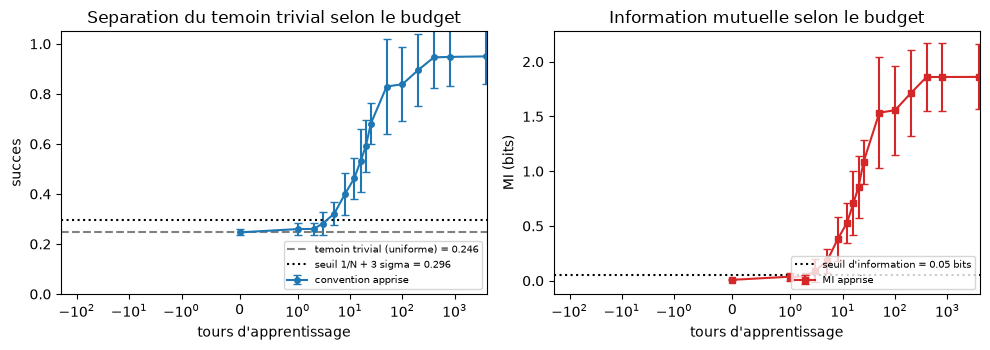

In [8]:
# --- Cadran d'identification (qualification des substrats, #24282, critere D2) ---
# Combien de tours faut-il pour que la convention apprise se SEPARE de la
# politique uniforme -- le temoin trivial du carnet ? Les sections precedentes
# rapportent l'etat FINAL (4000 tours) ; elles ne disent ni ou la separation
# commence, ni s'il existe un regime ou le temoin trivial reste optimal.
#
# Protocole : meme jeu, memes graines, memes instruments du carnet
# (success_rate, mutual_information) ; seule la QUANTITE de tours
# d'apprentissage varie. Le temoin (politique uniforme, sans apprentissage)
# ne depend pas du budget : on le mesure une fois par graine et reporte tel
# quel. Le critere de separation applique au bras appris est un seuil ABSOLU
# (succes > 1/N + 3 sigma, MI > 0.05 bit), et non une difference appariee avec
# le temoin : les deux bras partagent la graine, la fenetre de mesure et la
# temperature, mais l'instance de controle est une instance DISTINCTE (meme
# graine, pas le meme objet). Les valeurs par graine des DEUX bras sont
# conservees ici pour la comparaison appariee de la cellule suivante ; le
# tableau, lui, ne lit que le seuil.
#
# Le cadran descend jusqu'a un budget quasi nul : le point 0 est l'ancre, il
# reproduit le temoin trivial par construction (aucun apprentissage).
#
# Limite honnete : le budget coupe aussi le calendrier d'exploration (l'anneal
# de la temperature 0.6 -> 0.15 se fait sur n_rounds tours). Le cadran mesure
# donc un cout d'apprentissage TOTAL, exploration comprise, et non un cout
# d'identification pur.
BUDGETS = (0, 1, 2, 3, 5, 8, 12, 16, 20, 25, 50, 100, 200, 400, 800, 4000)
N_MESURE = 800
N_ETATS = 4

# Seuil de separation : le temoin trivial joue uniforme, donc son succes est
# 1/N ; l'ecart est retenu a 3 sigma binomiaux sur la fenetre de mesure.
sigma_succ = np.sqrt(0.25 * 0.75 / N_MESURE)
seuil_succ = 1.0 / N_ETATS + 3.0 * sigma_succ
# Seuil d'information : meme convention que la porte G2 du carnet (MI < 0.05
# bits = residu d'estimateur, aucune information).
seuil_mi = 0.05

# Le temoin trivial : agents sans apprentissage, politique uniforme. Il ne
# depend pas du budget -- on le mesure une fois par graine.
temoin = []
for gr in GRAINES:
    g_ctrl = sc.SignalingGame(N_ETATS, N_ETATS, temperature=0.6,
                               rng=np.random.default_rng(gr))
    temoin.append(mesure(g_ctrl, N_MESURE))
succ_temoin = float(np.mean([s for s, _ in temoin]))
mi_temoin = float(np.mean([m for _, m in temoin]))
print(f"temoin trivial (politique uniforme, sans apprentissage) : "
      f"succes={succ_temoin:.4f} +/- {np.std([s for s, _ in temoin], ddof=1):.4f} "
      f"| MI={mi_temoin:.4f} bits")
print(f"seuils : succes > {seuil_succ:.4f} | MI > {seuil_mi:.4f} bits")
print()

APPRIS = {}
lignes = []
for budget in BUDGETS:
    paires = []
    for gr in GRAINES:
        g = sc.SignalingGame(N_ETATS, N_ETATS, temperature=0.6,
                             rng=np.random.default_rng(gr))
        g.train(budget, anneal_to=0.15)
        paires.append(mesure(g, N_MESURE))
    succs = np.array([s for s, _ in paires])
    mis = np.array([m for _, m in paires])
    separes = int(np.sum((succs > seuil_succ) & (mis > seuil_mi)))
    lignes.append((budget, float(succs.mean()), float(succs.std(ddof=1)),
                   float(mis.mean()), float(mis.std(ddof=1)), separes))
    APPRIS[budget] = (succs.copy(), mis.copy())

print("budget | succes appris (moy +/- ecart) | MI apprise (moy +/- ecart) | graines separees")
for budget, s_moy, s_ect, m_moy, m_ect, sep in lignes:
    print(f"{budget:6d} | {s_moy:8.4f} +/- {s_ect:.4f} | "
          f"{m_moy:7.4f} +/- {m_ect:.4f} | {sep}/{len(GRAINES)}")
print()

# Le cadran : le plus petit budget ou la separation tient sur TOUTES les graines.
budgets_sep = [b for b, _, _, _, _, sep in lignes if sep == len(GRAINES)]
budget_croisiere = min(budgets_sep) if budgets_sep else None
print(f"budget de croisement (separation sur {len(GRAINES)}/{len(GRAINES)} graines) : "
      f"{budget_croisiere}")
separe_budgets = [b for b, _, _, _, _, sep in lignes if sep > 0]
print(f"premier budget ou AU MOINS une graine separe : {min(separe_budgets) if separe_budgets else None}")
print(f"regime trivial (aucune graine ne separe) : "
      f"{[b for b, _, _, _, _, sep in lignes if sep == 0]}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
budgets = [l[0] for l in lignes]
ax[0].errorbar(budgets, [l[1] for l in lignes], yerr=[l[2] for l in lignes],
               fmt="-o", ms=4, capsize=3, color="#1f77b4", label="convention apprise")
ax[0].axhline(succ_temoin, ls="--", color="grey",
               label=f"temoin trivial (uniforme) = {succ_temoin:.3f}")
ax[0].axhline(seuil_succ, ls=":", color="black",
               label=f"seuil 1/N + 3 sigma = {seuil_succ:.3f}")
ax[0].set_xscale("symlog", linthresh=1)
ax[0].set_title("Separation du temoin trivial selon le budget")
ax[0].set_xlabel("tours d'apprentissage") ; ax[0].set_ylabel("succes")
ax[0].set_ylim(0.0, 1.05) ; ax[0].legend(loc="lower right", fontsize=7)
ax[1].errorbar(budgets, [l[3] for l in lignes], yerr=[l[4] for l in lignes],
               fmt="-s", ms=4, capsize=3, color="#d62728", label="MI apprise")
ax[1].axhline(seuil_mi, ls=":", color="black",
               label=f"seuil d'information = {seuil_mi:.2f} bits")
ax[1].set_xscale("symlog", linthresh=1)
ax[1].set_title("Information mutuelle selon le budget")
ax[1].set_xlabel("tours d'apprentissage")
ax[1].set_ylabel("MI (bits)")
ax[1].legend(loc="lower right", fontsize=7)
fig.tight_layout() ; plt.show()


In [9]:
# --- Domaine de victoire du temoin : comparaison appariee par graine ---
succ_t = np.array([s for s, _ in temoin])
mi_t = np.array([m for _, m in temoin])
DELTA = 3.0 * sigma_succ
T95 = 2.776
# La marge pertinente est la bande de bruit 3 sigma de l instrument : en deca,
# les deux bras sont indiscernables (zone d equivalence), pas en avance.
print("temoin par graine (succes) : " + " | ".join(f"g{gr}:{s:.4f}" for gr, s in zip(GRAINES, succ_t)))
print("budget | dSucc moyen [IC95] | dMI moyen [IC95] | verdict (succes)")
ver_s = {}
for budget in BUDGETS:
    succs, mis = APPRIS[budget]
    ds = succs - succ_t
    dm = mis - mi_t
    bs = float(ds.mean()) - T95 * float(ds.std(ddof=1))
    hs = float(ds.mean()) + T95 * float(ds.std(ddof=1))
    bm = float(dm.mean()) - T95 * float(dm.std(ddof=1))
    hm = float(dm.mean()) + T95 * float(dm.std(ddof=1))
    if bs > DELTA:
        v = "appris bat le temoin (au-dela de la marge)"
    elif hs < -DELTA:
        v = "temoin bat l appris (au-dela de la marge)"
    elif bs > -DELTA and hs < DELTA:
        v = "equivalence dans la marge"
    else:
        v = "indetermine"
    ver_s[budget] = v
    print(f"{budget:6d} | {ds.mean():+.4f} [{bs:+.4f}; {hs:+.4f}] | {dm.mean():+.4f} [{bm:+.4f}; {hm:+.4f}] | {v}")
print()
print("premier budget ou l appris bat le temoin au-dela de la marge (succes) : " + str(next((b for b in BUDGETS if ver_s[b].startswith("appris bat")), None)))
print("budgets ou les deux bras sont indistinguables (succes) : " + str([b for b in BUDGETS if ver_s[b] == "equivalence dans la marge"]))
print("budgets ou le verdict reste indetermine (succes) : " + str([b for b in BUDGETS if ver_s[b] == "indetermine"]))
print("premier budget ou 5/5 graines franchissent le seuil de separation : " + str(budget_croisiere))


temoin par graine (succes) : g0:0.2412 | g1:0.2562 | g7:0.2300 | g42:0.2587 | g99:0.2462
budget | dSucc moyen [IC95] | dMI moyen [IC95] | verdict (succes)
     0 | +0.0000 [+0.0000; +0.0000] | +0.0000 [+0.0000; +0.0000] | equivalence dans la marge
     1 | +0.0133 [-0.0375; +0.0640] | +0.0286 [-0.0806; +0.1379] | indetermine
     2 | +0.0138 [-0.0358; +0.0633] | +0.0287 [-0.0802; +0.1375] | indetermine
     3 | +0.0353 [-0.0738; +0.1443] | +0.0847 [-0.2099; +0.3793] | indetermine
     5 | +0.0752 [-0.0680; +0.2185] | +0.1719 [-0.1315; +0.4753] | indetermine
     8 | +0.1537 [-0.0707; +0.3782] | +0.3713 [-0.1983; +0.9410] | indetermine
    12 | +0.2158 [-0.0216; +0.4531] | +0.5192 [-0.0063; +1.0448] | indetermine
    16 | +0.2863 [-0.0748; +0.6473] | +0.7009 [-0.1116; +1.5135] | indetermine
    20 | +0.3448 [+0.0417; +0.6478] | +0.8494 [+0.0618; +1.6371] | indetermine
    25 | +0.4350 [+0.1923; +0.6777] | +1.0771 [+0.5176; +1.6367] | appris bat le temoin (au-dela de la marge)
    50 | +

### Lecture — où commence la séparation, et quand le témoin est-il franchement dépassé

Le tableau se lit en trois temps.

**1. Un régime où rien n'est encore montré — pas un régime où le témoin est prouvé le meilleur.** À budget `0`, `1` et `2`, aucune des cinq graines ne franchit le seuil de séparation : la convention apprise reste dans le bruit du témoin. Ce que cela établit est négatif et précis : **le seuil n'est pas franchi**. Ce que cela n'établit pas : que la politique uniforme soit *meilleure*. La comparaison appariée par graine le dit — à une tour, l'écart de succès vaut `+0,0133` avec un intervalle à 95 % de `[-0,0375 ; +0,0640]` : l'intervalle traverse la marge de bruit de l'instrument, donc **ni la supériorité du témoin ni l'équivalence ne sont établies**. Le régime `0-2` est un régime d'**indétermination**, pas un régime de victoire du témoin.

**2. Deux frontières, et elles ne se confondent pas.** La **séparation** — le seuil absolu — commence à la troisième tour (`1/5` graines), se généralise (`2/5` à cinq tours, `4/5` à huit) et **tient sur les cinq graines à partir de douze tours**. La **supériorité** — l'écart apparié qui franchit la marge de bruit de l'instrument — n'est acquise qu'à **vingt-cinq tours** ; jusqu'à vingt tours inclus, l'intervalle à 95 % traverse encore la marge et le verdict y reste « indéterminé ». Deux questions, deux réponses : la convention *existe* à douze tours, elle *domine* le témoin à vingt-cinq. Le carnet disait « quatre mille tours » ; il peut maintenant dire « une douzaine de tours pour que la convention existe, vingt-cinq pour qu'elle batte le témoin, quatre cents pour qu'elle soit complète ».

**3. Deux temps, pas un.** Entre la séparation et le plafond, l'apprentissage ne se
contente pas de maintenir un avantage : il l'**améliore**. Le succès monte de `0.46`
(douze tours) à `0.95` (quatre cents), l'information de `0.53` à `1.86` bit, puis le
palier tient jusqu'à quatre mille tours. La séparation est un événement ; l'affinage
est un processus.

Ce que le cadran ajoute aux trois autres sections du carnet : le témoin trivial n'était
jusqu'ici qu'un **repère** (le `1/n` du §1, la porte G2 du §4bis) ; il devient un
**joueur** dont on mesure le domaine de victoire : franchement dépassé à partir de
vingt-cinq tours, indéterminé entre un et vingt tours. Et la multi-graine garde son rôle : la **séparation est robuste** (cinq graines sur cinq dès douze tours), l'**affinage ne
l'est pas** — c'est la graine 7 qui fait la dispersion des colonnes de droite, celle qui
reste au pooling partiel (succès `0.750`) bien après que les quatre autres ont convergé.
Le verdict `4/5` du carnet n'est donc pas un défaut du protocole : il habite **la phase
d'affinage**, pas la phase d'exister.

Une limite reste ouverte, et elle est celle qu'annonce la section : le budget coupe
le calendrier d'exploration avec lui (l'anneal de la température se fait sur `n_rounds`
tours). La frontière mesurée est donc celle du **coût d'apprentissage total**.

## À retenir

| Verdict | Ce qu'il montre | Contrôle falsifiant | Multi-graines (0/1/7/42/99) |
|---|---|---|---|
| **coordination_emerges** | Un code conventionnel émerge *sans* signification pré-inscrite | agents sans apprentissage (base $1/n$) | **4/5** — graine 7 : pooling partiel (succès 0.750) |
| **vocabulary_bottleneck** | Un vocabulaire insuffisant borne strictement la signification | vocab. suffisant vs limité | **5/5** — verdict le plus robuste |
| **mi_tracks_meaning** | Succès et information mutuelle croissent *ensemble* | état dominant : succès sans signification | **5/5** — écart MI ≥ 0.331 bit (seuil 0.3) |
| **convention_stability** | Une convention établie résiste aux chocs modérés | choc brutal qui l'effondre | **4/5** — même graine 7 (établi 0.750 < 0.8) |
| **gate de dégénérescence** (§4bis) | Les instruments savent lire un code connu | code identité imposé, code confondu, propensités uniformes | **4/4** portes PASSED |
| **cadran d'identification** (§5) | La convention apprise se sépare du témoin trivial à partir de douze tours ; en dessous, le témoin n'est pas **démontré** meilleur (comparaison appariée : verdict indéterminé) | témoin uniforme, même graine, même fenêtre de mesure | **5/5** — croisement à 12 tours, affinage complet à 400 |

***Leçon de l'expérience A** : avec un vocabulaire **fixe**, la signification
émerge bien — mais elle est **bornée** par $\log_2(n_{\text{signaux}})$. C'est
exactement la borne que l'expérience B (ICT-27-SymbolInvention-Python) lève en
laissant les agents **inventer** de nouveaux signaux à la mesure du problème.
Lewis (le donné) ouvre sur Skyrms (l'inventé).*

**Leçon multi-graines (#14439)** : sur 20 verdicts (4 tests × 5 graines),
**18 tiennent**. Les deux échecs (graine 7, §1 et §4) partagent la même racine —
un piège de pooling partiel où trois états sur quatre sont codés. La conclusion
centrale du notebook survit donc à la confrontation multi-graines, **mais pas à
l'unanimité** : sous ces paramètres exacts, une trajectoire d'apprentissage sur
cinq de cet échantillon ne code pas tous les états. C'est une propriété réelle
du mécanisme Roth-Erev (l'échappatoire au pooling n'est pas garantie), pas un
défaut de protocole — et c'est exactement ce que l'exercice 1 vous demande
d'explorer via la température.

***Leçon du cadran (§5)** : l'émergence n'est pas un état final, c'est un processus qui
a un prix. Sur ce terrain, une **douzaine de tours** suffisent à ce qu'une convention
existe et se distingue du témoin trivial, et quatre cents à ce qu'elle soit complète ;
en dessous, la convention apprise n'a pas encore d'avantage établi sur la politique
uniforme : le témoin n'est pas démontré meilleur, et l'écart apparié n'est pas non plus
établi — le verdict y est **indéterminé** (marge de bruit `3σ`, intervalle à 95 % qui
traverse la marge). La multi-graine se lit alors en deux temps : la **séparation** est
robuste (cinq graines sur cinq dès douze tours), l'**affinage** ne l'est pas.

## Vérifiez votre compréhension

1. Le verdict `mi_tracks_meaning` exige un écart d'information mutuelle ≥ 0.331 bit : pourquoi un taux de succès élevé, à lui seul, ne suffirait-il pas à conclure ?
2. 18 verdicts sur 20 tiennent sur 5 graines — que révèle la graine 7, et pourquoi ses deux échecs ont-ils la même racine ?
3. La leçon du carnet borne la signification par log2(n_signaux) : que fait l'expérience B (ICT-27) de cette borne ?

<details>
<summary>Réponses</summary>

1. Un taux de succès élevé est compatible avec un code qui **pool** les états : des agents peuvent réussir en convergeant sur des signaux qui n'informent pas (état dominant). L'information mutuelle croissante **avec** le succès est ce qui distingue une convention informative du pooling — d'où le seuil 0.3 bit (écart mesuré : 0.331 bit) et le contrôle de dégénérescence (4/4 PASSED) qui attestent que la performance n'est pas achetée par l'effondrement du code.
2. La graine 7 rate §1 et §4 par **pooling partiel** : 3 états sur 4 codés seulement, pour un succès de 0.750. C'est une propriété réelle du Roth-Erev — l'échappatoire au pooling n'est pas garanti par l'architecture — pas un défaut de protocole ; c'est précisément ce que l'exercice 1 (température) permet de manipuler.
3. Avec un vocabulaire de taille fixe, l'information transmise plafonne à log2(n_signaux) — le carnet le vérifie : la convention émergente sature la borne. ICT-27 donne aux agents le pouvoir d'**inventer** des signaux à la mesure du problème : de Lewis (convention donnée) à Skyrms (invention), la borne devient une variable.

</details>

Trois exercices pour rendre la convention opératoire. Chaque stub s'exécute
**sans erreur** (C.1) — il affiche un résultat partiel ou une amorce. Complétez
le `TODO` pour répondre à la question.

In [10]:
# Exercice 1 — La température discrimine-t-elle une convergence robuste d'un piège de pooling ?
# TODO: pour chaque température, entraîner un SignalingGame(4,4) et noter le succès final.
#       Une température trop haute maintient-elle l'exploration (pooling) ? Une trop basse fige-t-elle trop tôt ?
temperatures = [0.1, 0.3, 0.6, 1.0, 1.5]
for T in temperatures:
    g = sc.SignalingGame(4, 4, temperature=T, rng=np.random.default_rng(0))
    g.train(3000, anneal_to=0.15)
    print(f"T={T:.1f} -> succès final = {g.success_rate(800):.3f}")

T=0.1 -> succès final = 1.000


T=0.3 -> succès final = 1.000


T=0.6 -> succès final = 1.000


T=1.0 -> succès final = 1.000


T=1.5 -> succès final = 1.000


### Exercice 2 — Réussir *sans* signifier (le contrôle à état dominant)

Reproduisez vous-même le contrôle de la §3 : avec un état fortement dominant,
les agents atteignent un succès élevé mais une information mutuelle faible.
Constatez l'écart entre « réussir » et « signifier ».

In [11]:
# Exercice 2 — stub (compléter)
# TODO: construire une distribution avec un état dominant (ex. 0.85), entraîner,
#       et comparer succès vs I(état ; signal). Vérifier : succès haut, MI basse.
n_states = 4
dom_dist = np.full(n_states, (1.0 - 0.85) / (n_states - 1))
dom_dist[0] = 0.85  # l'état 0 pèse 85 %
g = sc.SignalingGame(n_states, n_states, temperature=0.6, state_dist=dom_dist,
                     rng=np.random.default_rng(0))
g.train(3000, anneal_to=0.15)
g.joint_state_signal[:] = 0.0
for _ in range(800):
    g.play_round(reinforce=False)
print(f"succès = {g.success_rate(800):.3f}   MI = {sc.mutual_information(g.joint_state_signal):.3f}   (max log2(4)=2.0)")
print("-> succès élevé MAIS MI faible : on réussit SANS signifier.")

succès = 0.954   MI = 0.706   (max log2(4)=2.0)
-> succès élevé MAIS MI faible : on réussit SANS signifier.


### Exercice 3 — L'échelle de l'espace d'états

La convention émerge-t-elle aussi pour des espaces d'états plus grands ? Balaiez
$n_{\text{états}}$ et observez si le succès final reste élevé — et combien de
l'information mutuelle se rapproche du plafond $\log_2(n)$.

In [12]:
# Exercice 3 — stub (compléter)
# TODO: pour chaque n_states, entraîner et noter succès + MI, comparer à log2(n).
for n in [2, 4, 6, 8]:
    g = sc.SignalingGame(n, n, temperature=0.6, rng=np.random.default_rng(0))
    g.train(4000, anneal_to=0.15)
    g.joint_state_signal[:] = 0.0
    for _ in range(800):
        g.play_round(reinforce=False)
    mi = sc.mutual_information(g.joint_state_signal)
    print(f"n_states={n} -> succès={g.success_rate(800):.3f}  MI={mi:.3f}  plafond log2({n})={np.log2(n):.3f}")

n_states=2 -> succès=1.000  MI=0.995  plafond log2(2)=1.000


n_states=4 -> succès=1.000  MI=1.993  plafond log2(4)=2.000


n_states=6 -> succès=1.000  MI=2.572  plafond log2(6)=2.585


n_states=8 -> succès=0.884  MI=2.707  plafond log2(8)=3.000


## Pour aller plus loin

- **[ICT-27 — Invention de symboles](ICT-27-SymbolInvention-Python.ipynb)** : l'expérience B de la strate 7 — les agents inventent les signaux que la convention laissait fixes.
- **[ICT-0 — Cadrage de la série](ICT-0-Framing.md)** : le principe directeur de la série ICT.
